# **Machine Learning & Neural Networks for Neuroscience – HW1**  
Gloria Yuyan Wu (EH5433675)

In [50]:
from pathlib import Path
import zipfile
import numpy as np
import h5py
import matplotlib.pyplot as plt

# Locate the ZIP file in Google Drive
zip_path = Path("/content/drive/MyDrive/dataset.zip")

# Extract the dataset to Colab
extract_dir = Path("/content/dataset")
extract_dir.mkdir(exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

# Find all recording sessions
data_files = sorted(extract_dir.rglob("*_spikes.mat"))

**1. From raw spikes to a tuning curve**

In [51]:
# Select the recording session
session_path = next(
    path for path in data_files
    if path.name == "106r001p26_spikes.mat"
)

with h5py.File(session_path, "r") as data:
    # The first spikes cell contains V1 responses
    references = np.asarray(data["spikes"]).ravel()
    v1 = data[references[0]]
    labels = np.asarray(data["stim"]).ravel().astype(int)

    # HDF5 dimensions: trials, time bins, neurons
    n_trials, n_time_bins, n_neurons = v1.shape

    assert n_time_bins == 1280
    assert labels.size == n_trials

    spike_counts = np.empty(
        (n_neurons, n_trials), dtype=np.int64
    )

    # Sum spikes across the 1280-ms stimulus period
    for start in range(0, n_trials, 100):
        stop = min(start + 100, n_trials)
        spike_counts[:, start:stop] = (
            v1[start:stop].sum(axis=1).T
        )

print("Number of V1 units:", n_neurons)
print("Spike count shape:", spike_counts.shape)

Number of V1 units: 109
Spike count shape: (109, 3200)


In [52]:
# Documented orientation mapping for this session
angles = np.array([
    0, 22.5, 45, 67.5, 90, 112.5, 135, 157.5
])

mean_responses = np.empty((n_neurons, len(angles)))

print("Orientation (deg) | Trials")

for j, angle in enumerate(angles):
    # Select trials with stimulus code j + 1
    mask = labels == j + 1

    # Average trial spike counts for each neuron
    mean_responses[:, j] = spike_counts[:, mask].mean(axis=1)

    print(f"{angle:>18g} {mask.sum():>8}")

Orientation (deg) | Trials
                 0      400
              22.5      400
                45      400
              67.5      400
                90      400
             112.5      400
               135      400
             157.5      400


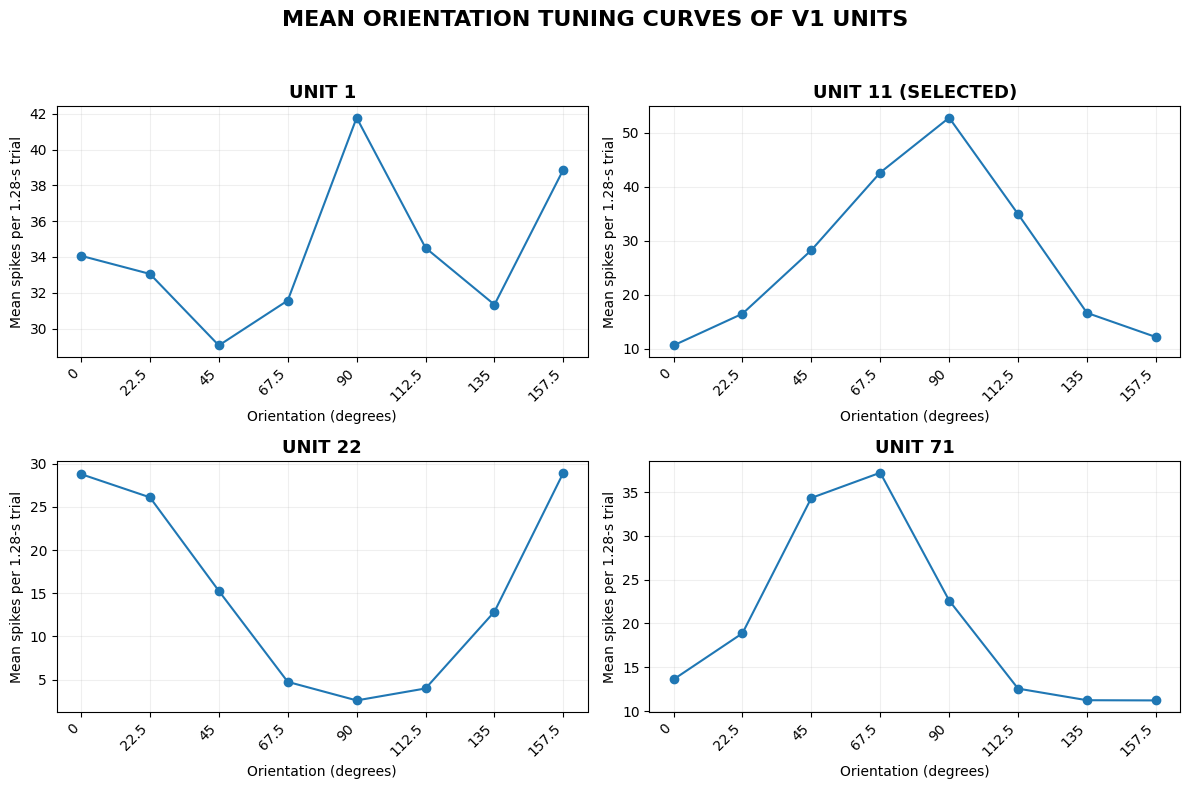

In [53]:
# Plot several neurons
example_units = [1, 11, 22, 71]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, unit in zip(axes.flat, example_units):
    index = unit - 1

    ax.plot(angles, mean_responses[index], "o-")

    title = f"UNIT {unit}"
    if unit == candidate_unit:
        title += " (SELECTED)"

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("Orientation (degrees)")
    ax.set_ylabel("Mean spikes per 1.28-s trial")

    ax.set_xticks(angles)
    ax.set_xticklabels(
        [f"{angle:g}" for angle in angles],
        rotation=45,
        ha="right"
    )

    ax.grid(alpha=0.2)

fig.suptitle(
    "MEAN ORIENTATION TUNING CURVES OF V1 UNITS",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout(rect=[0, 0, 1, 0.95])

# Save the figure for the report
fig.savefig(
    "/content/part1_tuning_curves.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [54]:
# Select a neuron after inspecting the tuning curves
candidate_unit = 11
candidate_index = candidate_unit - 1

# Display the selected neuron's mean responses
selected_response = mean_responses[candidate_index]

print("Selected unit:", candidate_unit)
print("Orientation (deg) | Mean spikes/trial")

for angle, response in zip(angles, selected_response):
    print(angle, "|", round(response, 4))

peak = np.argmax(selected_response)



Selected unit: 11
Orientation (deg) | Mean spikes/trial
0.0 | 10.585
22.5 | 16.45
45.0 | 28.22
67.5 | 42.595
90.0 | 52.7475
112.5 | 34.8975
135.0 | 16.6075
157.5 | 12.1375


**2. Polynomial regression**

In [55]:
# Prepare the selected neuron's data for fitting
x = angles
y = mean_responses[candidate_index]

In [56]:
from numpy.polynomial import Polynomial

degrees = [1, 3, 4, 7]
models = {}
mse_values = {}

for degree in degrees:
    # Fit a polynomial by least squares
    model = Polynomial.fit(x, y, deg=degree)
    models[degree] = model

    # Evaluate predictions at the measured orientations
    predicted = model(x)

    # Calculate training MSE across the eight mean responses
    mse_values[degree] = np.mean((y - predicted) ** 2)

print("Polynomial order | Parameters | MSE")

for degree in degrees:
    print(degree, "|", degree + 1, "|", f"{mse_values[degree]:.6g}")

Polynomial order | Parameters | MSE
1 | 2 | 208.605
3 | 4 | 39.3378
4 | 5 | 7.18765
7 | 8 | 3.16491e-27


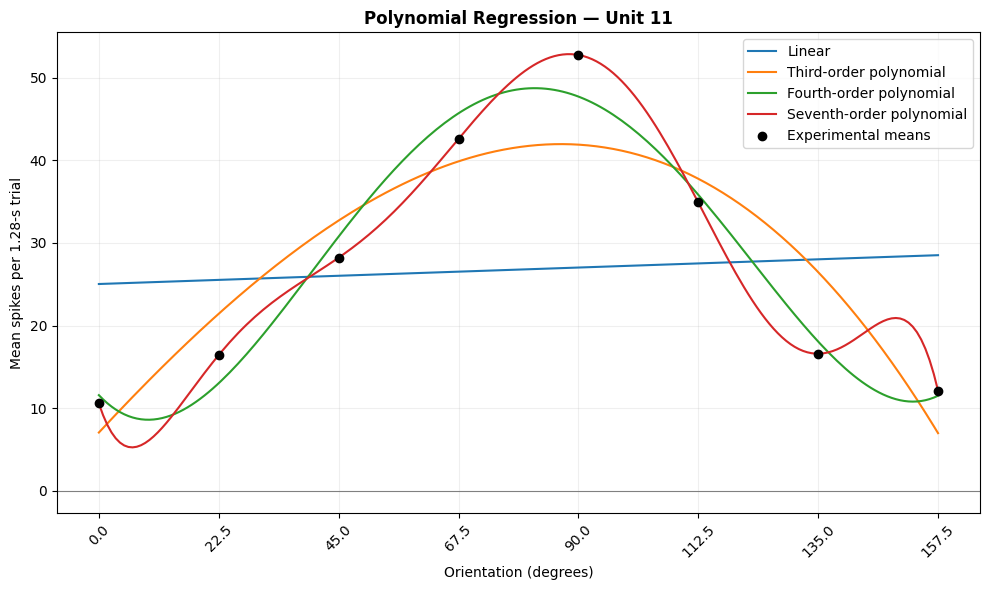

In [57]:
# Generate a dense angle grid for displaying fitted curves
x_curve = np.linspace(x.min(), x.max(), 200)

# Define labels for each polynomial model
order_labels = {
    1: "Linear",
    3: "Third-order polynomial",
    4: "Fourth-order polynomial",
    7: "Seventh-order polynomial"
}

fig, ax = plt.subplots(figsize=(10, 6))

# Plot all four fitted functions
for degree in degrees:
    ax.plot(
        x_curve,
        models[degree](x_curve),
        label=order_labels[degree]
    )

# Plot the experimental mean responses
ax.scatter(
    x,
    y,
    color="black",
    zorder=5,
    label="Experimental means"
)

# Set axis labels
ax.set_xlabel("Orientation (degrees)")
ax.set_ylabel("Mean spikes per 1.28-s trial")

# Set title
ax.set_title(
    "Polynomial Regression — Unit " + str(candidate_unit),
    fontweight="bold"
)

# Set x-axis ticks
ax.set_xticks(x)
ax.tick_params(axis="x", labelrotation=45)

# Add reference line, grid, and legend
ax.axhline(0, color="gray", linewidth=0.8)
ax.grid(alpha=0.2)
ax.legend()

fig.tight_layout()

# Save the figure for the report
fig.savefig(
    "/content/part2_polynomial_fits.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**3. Nonlinear regression **

In [58]:
from scipy.optimize import curve_fit

# Define the Gaussian function
def gaussian(theta, B, A, mu, sigma):
    return B + A * np.exp(-((theta - mu)**2) / (2 * sigma**2))

# Set initial guesses and parameter bounds
initial_guess = [min(y), max(y) - min(y), x[np.argmax(y)], 20]

lower_bounds = [0, 0, 0, 0.001]
upper_bounds = [np.inf, np.inf, 180, np.inf]

# Fit the Gaussian model
parameters, _ = curve_fit(
    gaussian,
    x,
    y,
    p0=initial_guess,
    bounds=(lower_bounds, upper_bounds)
)

# Extract fitted parameters
B, A, mu, sigma = parameters

# Calculate fitted responses
y_fit = gaussian(x, B, A, mu, sigma)

# Print fitted parameters
print("B:", round(B, 4), "spikes/trial")
print("A:", round(A, 4), "spikes/trial")
print("mu:", round(mu, 4), "degrees")
print("sigma:", round(sigma, 4), "degrees")

B: 10.8417 spikes/trial
A: 40.8697 spikes/trial
mu: 83.6669 degrees
sigma: 28.0371 degrees


In [59]:
# Calculate Gaussian training MSE
gaussian_predictions = gaussian(x, *parameters)
gaussian_mse = np.mean((y - gaussian_predictions) ** 2)

# Define model names
model_names = {
    1: "Linear",
    3: "Third-order polynomial",
    4: "Fourth-order polynomial",
    7: "Seventh-order polynomial"
}

# Compare all fitted models
print("Model | Parameters | Training MSE")

for order, name in model_names.items():
    print(name, "|", order + 1, "|", round(mse_values[order], 6))

print("Gaussian", "|", 4, "|", round(gaussian_mse, 6))

Model | Parameters | Training MSE
Linear | 2 | 208.605253
Third-order polynomial | 4 | 39.337782
Fourth-order polynomial | 5 | 7.187652
Seventh-order polynomial | 8 | 0.0
Gaussian | 4 | 2.794527


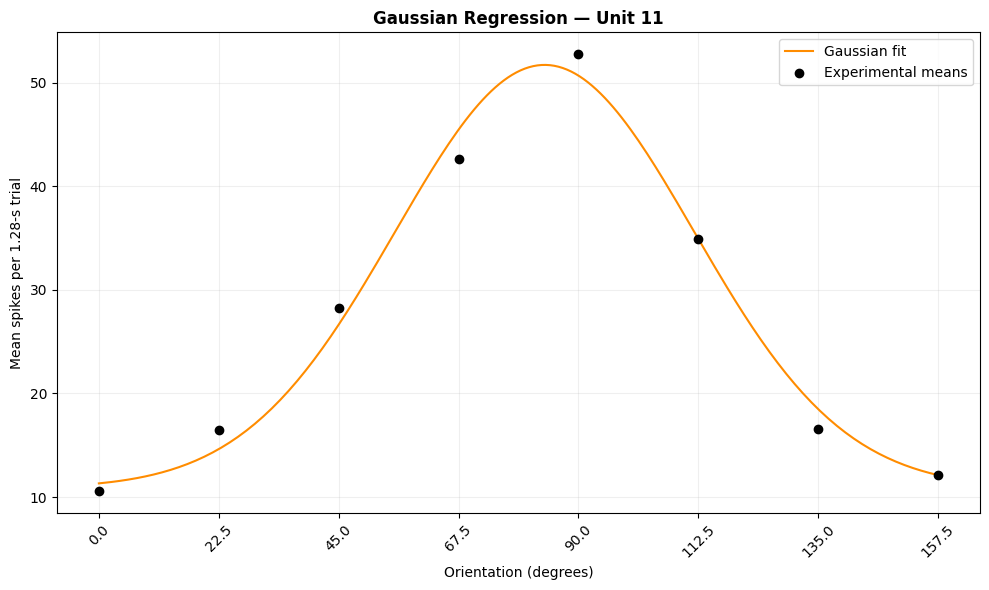

In [60]:
# Generate angles for displaying the fitted curve
x_curve = np.linspace(x.min(), x.max(), 200)

fig, ax = plt.subplots(figsize=(10, 6))

# Plot the fitted Gaussian
ax.plot(
    x_curve,
    gaussian(x_curve, *parameters),
    color="darkorange",
    label="Gaussian fit"
)

# Plot the observed mean responses
ax.scatter(
    x,
    y,
    color="black",
    zorder=5,
    label="Experimental means"
)

# Set axis labels
ax.set_xlabel("Orientation (degrees)")
ax.set_ylabel("Mean spikes per 1.28-s trial")

# Set title
ax.set_title(
    "Gaussian Regression — Unit " + str(candidate_unit),
    fontweight="bold"
)

# Set x-axis ticks
ax.set_xticks(x)
ax.tick_params(axis="x", labelrotation=45)

ax.grid(alpha=0.2)
ax.legend()

fig.tight_layout()

# Save the figure for the report
fig.savefig(
    "/content/part3_gaussian_fit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**4. A problem with orientation **

In [61]:
# Define the von Mises tuning function
def von_mises(theta, B, A, mu, kappa):
    angle_difference = np.deg2rad(theta - mu)

    return B + A * np.exp(kappa * np.cos(2 * angle_difference))


# Set initial guesses
initial_guess = [
    min(y),
    (max(y) - min(y)) / np.exp(1),
    x[np.argmax(y)],
    1
]

# Set parameter bounds
lower_bounds = [0, 0, 0, 0]
upper_bounds = [np.inf, np.inf, 180, np.inf]


# Fit the von Mises model
parameters_vm, _ = curve_fit(
    von_mises,
    x,
    y,
    p0=initial_guess,
    bounds=(lower_bounds, upper_bounds)
)


# Extract fitted parameters
B_vm, A_vm, mu_vm, kappa = parameters_vm


# Print fitted parameters
print("B:", round(B_vm, 4), "spikes/trial")
print("A:", round(A_vm, 4), "spikes/trial")
print("mu:", round(mu_vm, 4), "degrees")
print("kappa:", round(kappa, 4))

B: 4.2644 spikes/trial
A: 17.9314 spikes/trial
mu: 83.7657 degrees
kappa: 0.9814


In [62]:
# Predict responses at the measured orientations
circular_predictions = von_mises(
    x, *circular_parameters
)

# Calculate training MSE
circular_mse = np.mean(
    (y - circular_predictions) ** 2
)

print("Model | Training MSE")
print("Gaussian |", round(gaussian_mse, 6))
print("von Mises |", round(circular_mse, 6))

Model | Training MSE
Gaussian | 2.794527
von Mises | 2.633227


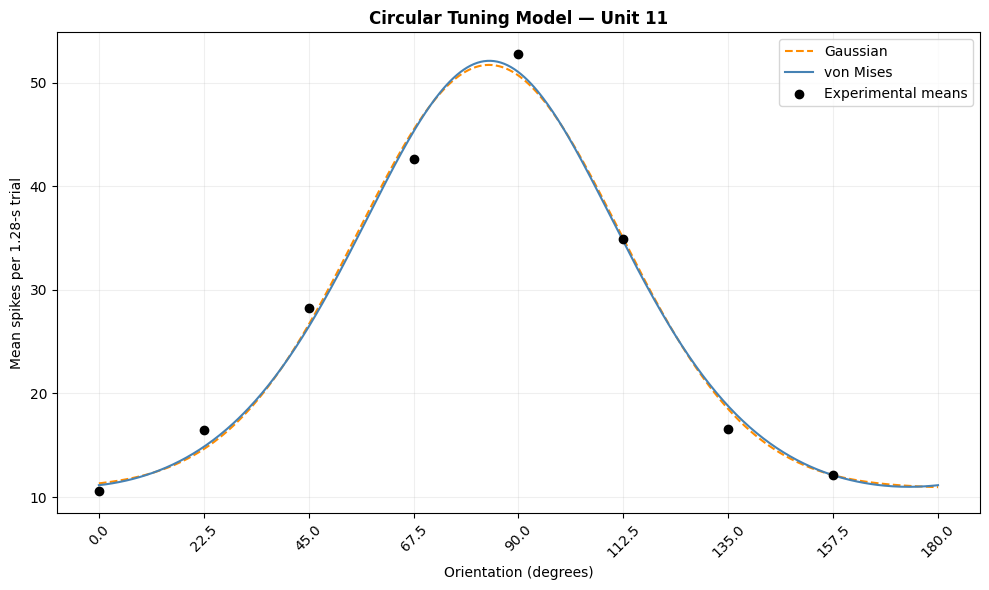

In [63]:
# Display both models over one orientation cycle
x_curve = np.linspace(0, 180, 500)

fig, ax = plt.subplots(figsize=(10, 6))

# Plot the Gaussian model
ax.plot(
    x_curve,
    gaussian(x_curve, *parameters),
    "--",
    color="darkorange",
    label="Gaussian"
)

# Plot the von Mises model
ax.plot(
    x_curve,
    von_mises(x_curve, *circular_parameters),
    color="steelblue",
    label="von Mises"
)

# Plot the experimental mean responses
ax.scatter(
    x,
    y,
    color="black",
    zorder=5,
    label="Experimental means"
)

# Set axis labels
ax.set_xlabel("Orientation (degrees)")
ax.set_ylabel("Mean spikes per 1.28-s trial")

# Set title
ax.set_title(
    "Circular Tuning Model — Unit " + str(candidate_unit),
    fontweight="bold"
)

# Set x-axis ticks
ticks = np.append(angles, 180)
ax.set_xticks(ticks)
ax.tick_params(axis="x", labelrotation=45)

ax.grid(alpha=0.2)
ax.legend()

fig.tight_layout()

# Save the figure for the report
fig.savefig(
    "/content/part4_von_mises_fit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**5. Comparing the models and evaluating generalization **

In [64]:
# Summarize models fitted to Unit 11
model_summary = [
    ("Linear", 2, mse_values[1], "No", "No"),
    ("Third-order polynomial", 4, mse_values[3], "No", "No"),
    ("Fourth-order polynomial", 5, mse_values[4], "No", "No"),
    ("Seventh-order polynomial", 8, mse_values[7], "No", "No"),
    ("Gaussian", 4, gaussian_mse, "Yes", "No"),
    ("von Mises", 4, circular_mse, "Yes", "Yes")
]

# Print model comparison
print("Model | Parameters | Training MSE | Interpretable | Circular")

for name, count, mse, interpretable, circular in model_summary:
    print(name, "|", count, "|", round(mse, 6), "|", interpretable, "|", circular)

Model | Parameters | Training MSE | Interpretable | Circular
Linear | 2 | 208.605253 | No | No
Third-order polynomial | 4 | 39.337782 | No | No
Fourth-order polynomial | 5 | 7.187652 | No | No
Seventh-order polynomial | 8 | 0.0 | No | No
Gaussian | 4 | 2.794527 | Yes | No
von Mises | 4 | 2.633227 | Yes | Yes


In [65]:
# Calculate Fano factors separately for each orientation
fano_factors = np.full((n_neurons, len(angles)), np.nan)

for j, code in enumerate(range(1, 9)):
    responses = spike_counts[:, labels == code]

    mean_counts = responses.mean(axis=1)
    count_variances = responses.var(axis=1, ddof=1)

    # Fano factor is undefined when the mean count is zero
    np.divide(
        count_variances,
        mean_counts,
        out=fano_factors[:, j],
        where=mean_counts > 0
    )

# Require a defined Fano factor at all eight orientations
valid = np.isfinite(fano_factors).all(axis=1)

mean_fano = np.full(n_neurons, np.nan)
mean_fano[valid] = fano_factors[valid].mean(axis=1)

# Rank valid units by their mean Fano factor
original_index = 10  # Unit 11
eligible_indices = np.flatnonzero(valid)
eligible_indices = eligible_indices[
    eligible_indices != original_index
]

ranked_indices = eligible_indices[
    np.argsort(mean_fano[eligible_indices])[::-1]
]

additional_indices = ranked_indices[:2]

units_to_compare = [
    11,
    *[int(index + 1) for index in additional_indices]
]

print("Unit | Mean Fano Factor")

for unit in units_to_compare:
    print(unit, "|", round(mean_fano[unit - 1], 4))

Unit | Mean Fano Factor
11 | 3.2772
74 | 19.8366
44 | 7.8948


In [66]:
# Store fitting results
fit_results = {}
mse_rows = []

# Set parameter bounds
gaussian_bounds = ([0, 0, 0, 0.001],
                   [np.inf, np.inf, 180, np.inf])

circular_bounds = ([0, 0, 0, 0],
                   [np.inf, np.inf, 180, np.inf])


# Fit three models to each unit
for unit in units_to_compare:

    response = mean_responses[unit - 1]

    # Polynomial regression
    polynomial = Polynomial.fit(x, response, 7)

    # Gaussian regression
    gaussian_start = [
        min(response),
        max(response) - min(response),
        x[np.argmax(response)],
        25
    ]

    gaussian_params, _ = curve_fit(
        gaussian, x, response,
        p0=gaussian_start,
        bounds=gaussian_bounds
    )

    # von Mises regression
    circular_start = [
        min(response),
        (max(response) - min(response)) / np.exp(1),
        x[np.argmax(response)],
        1
    ]

    circular_params, _ = curve_fit(
        von_mises, x, response,
        p0=circular_start,
        bounds=circular_bounds
    )

    # Save fitted models
    fit_results[unit] = (polynomial, gaussian_params, circular_params)

    # Calculate training MSE
    predictions = {
        "Polynomial": polynomial(x),
        "Gaussian": gaussian(x, *gaussian_params),
        "von Mises": von_mises(x, *circular_params)
    }

    for name, prediction in predictions.items():
        mse = np.mean((response - prediction) ** 2)
        mse_rows.append([unit, name, mse])


# Print results
print("Unit | Model | Training MSE")

for unit, name, mse in mse_rows:
    print(unit, "|", name, "|", round(mse, 6))

Unit | Model | Training MSE
11 | Polynomial | 0.0
11 | Gaussian | 2.794527
11 | von Mises | 2.633227
74 | Polynomial | 0.0
74 | Gaussian | 1.428919
74 | von Mises | 1.194306
44 | Polynomial | 0.0
44 | Gaussian | 10.790024
44 | von Mises | 10.183048


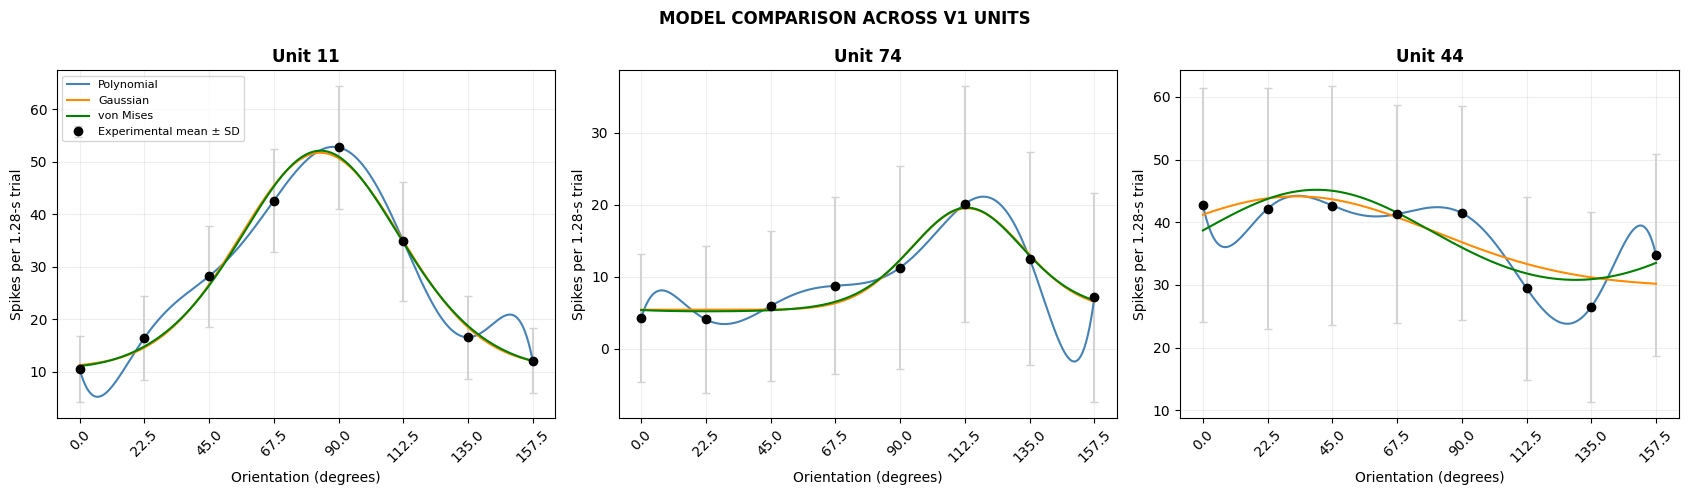

In [68]:
units_to_compare = [11, 74, 44]

# Calculate trial-to-trial SD
trial_sd = np.column_stack([
    spike_counts[:, labels == code].std(axis=1, ddof=1)
    for code in range(1, 9)
])

# Create smooth x values for plotting
x_curve = np.linspace(min(x), max(x), 500)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))


# Plot each neuron
for ax, unit in zip(axes, units_to_compare):

    index = unit - 1
    polynomial, gaussian_params, circular_params = fit_results[unit]

    # Plot experimental data with SD
    ax.errorbar(
        x,
        mean_responses[index],
        yerr=trial_sd[index],
        fmt="ko",
        ecolor="lightgray",
        capsize=3,
        label="Experimental mean ± SD"
    )

    # Polynomial fit
    ax.plot(
        x_curve,
        polynomial(x_curve),
        color="steelblue",
        label="Polynomial"
    )

    # Gaussian fit
    ax.plot(
        x_curve,
        gaussian(x_curve, *gaussian_params),
        color="darkorange",
        label="Gaussian"
    )

    # von Mises fit
    ax.plot(
        x_curve,
        von_mises(x_curve, *circular_params),
        color="green",
        label="von Mises"
    )

    # Set titles and labels
    ax.set_title("Unit " + str(unit), fontweight="bold")
    ax.set_xlabel("Orientation (degrees)")
    ax.set_ylabel("Spikes per 1.28-s trial")

    # Set x-axis ticks
    ax.set_xticks(x)
    ax.tick_params(axis="x", labelrotation=45)

    ax.grid(alpha=0.2)


# Add legend
axes[0].legend(fontsize=8)

# Main title
fig.suptitle(
    "MODEL COMPARISON ACROSS V1 UNITS",
    fontsize=16,
    fontweight="bold"
)

fig.tight_layout()

# Save figure
fig.savefig(
    "/content/part5_neuron_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()